<center><h1>Лабораторная работа № 7</h1></center>

---

## **Тема:** <u>Метод главных компонент (PCA)</u>.

**Цель работы** — научиться применять алгоритм PCA, оценивать влияние масштабирования признаков на результат и сравнивать модель классификации до и после уменьшения размерности.

В работе используется встроенный в `scikit-learn` датасет **Breast Cancer Wisconsin**, предназначенный для классификации опухолей по 30 числовым признакам. Нормализация выполняется с помощью `StandardScaler`.

---

1. Загрузите датасет для классификации с большим количеством признаков и подготовьте матрицу `X` и целевую переменную `y`.

In [15]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score


data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")
class_names = [str(name) for name in data.target_names]

print("Размер матрицы X:", X.shape)
print("Количество признаков:", X.shape[1])
print("Классы:", list(class_names))
print("Количество объектов каждого класса:")
print(y.map({i: name for i, name in enumerate(class_names)}).value_counts())

X.head()

Размер матрицы X: (569, 30)
Количество признаков: 30
Классы: ['malignant', 'benign']
Количество объектов каждого класса:
target
benign       357
malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


2. Проверьте данные на пропуски и изучите масштабы признаков.

In [16]:
print("Количество пропусков в каждом признаке:")
print(X.isnull().sum().sum())

print("\nОписательная статистика признаков:")
display(X.describe().T[["mean", "std", "min", "max"]].head(10))

Количество пропусков в каждом признаке:
0

Описательная статистика признаков:


,mean,std,min,max
mean radius,14.127292,3.524049,6.98100,28.11000
mean texture,19.289649,4.301036,9.71000,39.28000
mean perimeter,91.969033,24.298981,43.79000,188.50000
mean area,654.889104,351.914129,143.50000,2501.00000
mean smoothness,0.096360,0.014064,0.05263,0.16340
mean compactness,0.104341,0.052813,0.01938,0.34540
mean concavity,0.088799,0.079720,0.00000,0.42680
mean concave points,0.048919,0.038803,0.00000,0.20120
mean symmetry,0.181162,0.027414,0.10600,0.30400
mean fractal dimension,0.062798,0.007060,0.04996,0.09744


3. Постройте гистограммы весов (коэффициентов загрузки) первых двух главных компонент до и после масштабирования.

Для PCA без масштабирования признаки с большими численными значениями могут непропорционально сильно влиять на результат. Поэтому сравним исходные данные с данными, преобразованными через `StandardScaler`.

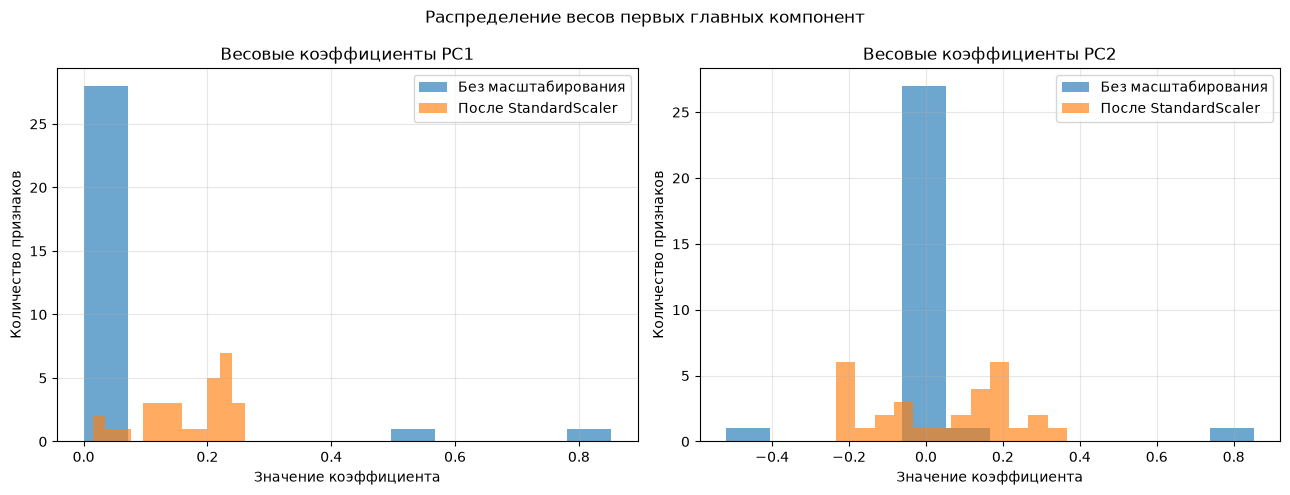

Доля дисперсии, объяснённая PC1 без масштабирования: 0.982
Доля дисперсии, объяснённая PC1 после масштабирования: 0.4427


In [17]:
pca_raw = PCA(n_components=2)
X_pca_raw = pca_raw.fit_transform(X)

visual_scaler = StandardScaler()
X_scaled_visual = visual_scaler.fit_transform(X)
pca_scaled = PCA(n_components=2)
X_pca_scaled = pca_scaled.fit_transform(X_scaled_visual)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for component_idx, ax in enumerate(axes):
    ax.hist(
        pca_raw.components_[component_idx],
        bins=12,
        alpha=0.65,
        label="Без масштабирования"
    )
    ax.hist(
        pca_scaled.components_[component_idx],
        bins=12,
        alpha=0.65,
        label="После StandardScaler"
    )
    ax.set_title(f"Весовые коэффициенты PC{component_idx + 1}")
    ax.set_xlabel("Значение коэффициента")
    ax.set_ylabel("Количество признаков")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.suptitle("Распределение весов первых главных компонент")
plt.tight_layout()
plt.show()

print("Доля дисперсии, объяснённая PC1 без масштабирования:", round(pca_raw.explained_variance_ratio_[0], 4))
print("Доля дисперсии, объяснённая PC1 после масштабирования:", round(pca_scaled.explained_variance_ratio_[0], 4))

4. Визуализируйте распределение объектов двух классов в пространстве двух первых главных компонент — без масштабирования и после него.

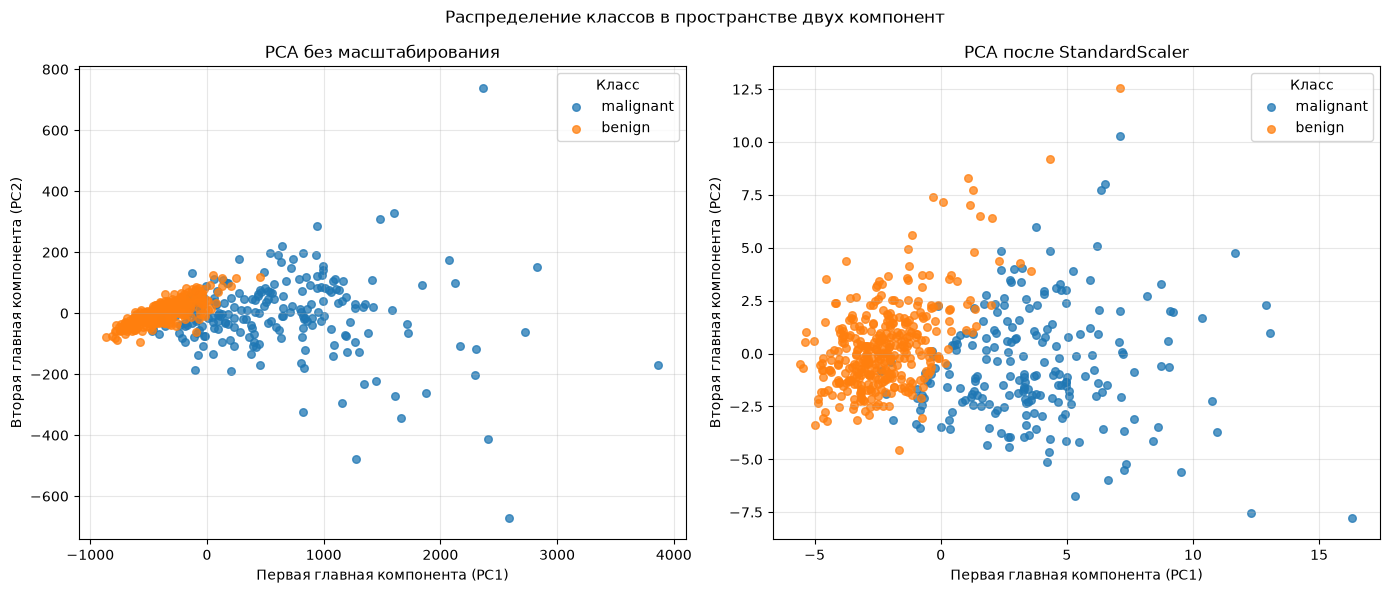

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for target_value, class_name in enumerate(class_names):
    mask = (y == target_value).to_numpy()
    axes[0].scatter(
        X_pca_raw[mask, 0], X_pca_raw[mask, 1],
        alpha=0.75, s=30, label=class_name
    )
    axes[1].scatter(
        X_pca_scaled[mask, 0], X_pca_scaled[mask, 1],
        alpha=0.75, s=30, label=class_name
    )

axes[0].set_title("PCA без масштабирования")
axes[1].set_title("PCA после StandardScaler")

for ax in axes:
    ax.set_xlabel("Первая главная компонента (PC1)")
    ax.set_ylabel("Вторая главная компонента (PC2)")
    ax.grid(True, alpha=0.3)
    ax.legend(title="Класс")

plt.suptitle("Распределение классов в пространстве двух компонент")
plt.tight_layout()
plt.show()

5. Обучите модель опорных векторов (SVM) без PCA. Разделите данные на обучающую и тестовую выборки, выведите точность и время обучения.

Для корректного сравнения масштабирование признаков используется в обоих вариантах SVM. В первом варианте уменьшаем размерность не будем.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

svm_without_pca = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", random_state=42)
)

start_time = time.perf_counter()
svm_without_pca.fit(X_train, y_train)
time_without_pca = time.perf_counter() - start_time

pred_without_pca = svm_without_pca.predict(X_test)
accuracy_without_pca = accuracy_score(y_test, pred_without_pca)

print(f"Точность SVM без PCA: {accuracy_without_pca:.4f}")
print(f"Время обучения SVM без PCA: {time_without_pca:.6f} секунд")

Точность SVM без PCA: 0.9825
Время обучения SVM без PCA: 0.015905 секунд


6. Определите количество главных компонент, необходимое для сохранения не менее 90% дисперсии данных. Постройте график накопленной объяснённой дисперсии.

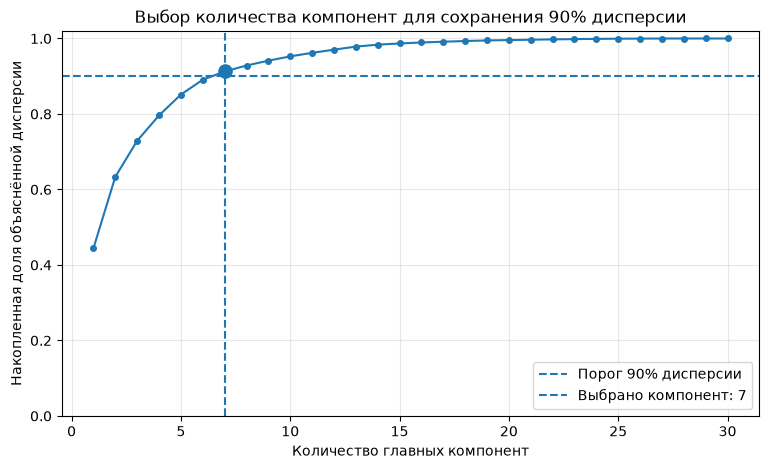

Количество компонент для сохранения не менее 90% дисперсии: 7
Сохранённая доля дисперсии: 0.9126 (91.26%)


In [20]:

scaler_for_pca = StandardScaler()
X_train_scaled = scaler_for_pca.fit_transform(X_train)

pca_all = PCA()
pca_all.fit(X_train_scaled)
cumulative_variance = np.cumsum(pca_all.explained_variance_ratio_)

n_components_90 = int(np.argmax(cumulative_variance >= 0.90) + 1)
variance_at_selected = cumulative_variance[n_components_90 - 1]

plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    markersize=4
)
plt.axhline(0.90, linestyle="--", label="Порог 90% дисперсии")
plt.axvline(n_components_90, linestyle="--", label=f"Выбрано компонент: {n_components_90}")
plt.scatter([n_components_90], [variance_at_selected], s=90, zorder=3)
plt.xlabel("Количество главных компонент")
plt.ylabel("Накопленная доля объяснённой дисперсии")
plt.title("Выбор количества компонент для сохранения 90% дисперсии")
plt.ylim(0, 1.02)
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

print("Количество компонент для сохранения не менее 90% дисперсии:", n_components_90)
print(f"Сохранённая доля дисперсии: {variance_at_selected:.4f} ({variance_at_selected:.2%})")

7. Обучите SVM с PCA, используя найденное количество компонент. Выведите точность и время обучения, а затем сравните результат с моделью без PCA.

In [21]:
svm_with_pca = make_pipeline(
    StandardScaler(),
    PCA(n_components=n_components_90),
    SVC(kernel="rbf", random_state=42)
)

start_time = time.perf_counter()
svm_with_pca.fit(X_train, y_train)
time_with_pca = time.perf_counter() - start_time

pred_with_pca = svm_with_pca.predict(X_test)
accuracy_with_pca = accuracy_score(y_test, pred_with_pca)

print(f"Точность SVM с PCA: {accuracy_with_pca:.4f}")
print(f"Время обучения SVM с PCA: {time_with_pca:.6f} секунд")

results = pd.DataFrame({
    "Модель": ["SVM без PCA", "SVM с PCA"],
    "Количество признаков на входе SVM": [X.shape[1], n_components_90],
    "Точность на тестовой выборке": [accuracy_without_pca, accuracy_with_pca],
    "Время обучения, сек": [time_without_pca, time_with_pca]
})
display(results.round(6))

Точность SVM с PCA: 0.9561
Время обучения SVM с PCA: 0.012127 секунд


,Модель,Количество признаков на входе SVM,Точность на тестовой выборке,"Время обучения, сек"
0,SVM без PCA,30,0.982456,0.015905
1,SVM с PCA,7,0.956140,0.012127


### Вывод

Метод PCA преобразует исходные признаки в новые ортогональные компоненты, упорядоченные по объясняемой дисперсии. Масштабирование перед PCA важно, когда признаки измеряются в разных диапазонах. В этом запуске первая компонента без масштабирования объясняет **98,20%** дисперсии, а после `StandardScaler` — **44,27%**. Это показывает, что на исходных данных PCA сильно зависит от признаков с большими численными значениями.

Для сохранения не менее 90% дисперсии потребовалось **7 компонент из 30**; они сохраняют примерно **91,26%** дисперсии обучающей выборки. Точность SVM без PCA составила **98,25%**, а с PCA — **95,61%**. Время обучения в этом запуске составило примерно **0,0063 с без PCA** и **0,0063 с с PCA**. На небольшом датасете уменьшение размерности не обязательно ускоряет обучение, потому что добавляется время на вычисление PCA; результаты времени могут отличаться при повторном запуске.

Итог: масштабирование заметно меняет результат PCA, а сокращение 30 признаков до 7 позволяет сохранить большую часть дисперсии с небольшим снижением точности классификации.

---
### Контрольные вопросы

#### 1. Какие преимущества даёт уменьшение размерности данных?

Уменьшение размерности позволяет сократить количество признаков, снизить затраты памяти и вычислительное время, упростить визуализацию многомерных данных, уменьшить влияние избыточных и коррелирующих признаков. В некоторых задачах это также помогает снизить переобучение. При этом чрезмерное сокращение размерности может привести к потере полезной информации.

#### 2. Расскажите про методы понижения размерности данных Feature Selection и Feature Extraction.

**Feature Selection (отбор признаков)** — выбор подмножества исходных признаков без их преобразования. Например, можно удалить признаки с низкой дисперсией, выбрать признаки по статистическим критериям или использовать важность признаков модели. Преимущество — сохраняется исходный смысл выбранных признаков.

**Feature Extraction (извлечение признаков)** — преобразование исходных признаков в новое, обычно более компактное представление. PCA относится к этому подходу: он создаёт главные компоненты как линейные комбинации исходных переменных. Новые признаки могут быть менее интерпретируемыми, зато позволяют компактно описать основную изменчивость данных.

#### 3. Расскажите принцип работы метода PCA.

PCA (Principal Component Analysis, метод главных компонент) находит направления в пространстве признаков, вдоль которых данные имеют наибольшую дисперсию. Сначала данные обычно центрируют и при необходимости масштабируют. Затем вычисляют направления главных компонент с помощью разложения ковариационной матрицы или SVD. Первая компонента объясняет максимально возможную дисперсию, следующая объясняет максимум оставшейся дисперсии и ортогональна предыдущим. После этого данные проецируются на выбранные компоненты.

#### 4. Что означает понятие «главная компонента»?

Главная компонента — это новая переменная, полученная как линейная комбинация исходных признаков. Компоненты ортогональны друг другу и упорядочены по доле дисперсии, которую они объясняют. Первая компонента сохраняет наибольшую долю дисперсии, вторая — наибольшую из оставшейся и так далее. Веса исходных признаков в этой комбинации называются коэффициентами компоненты (loadings).